# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Decision Tree - Predicting Time of Day and Next Track
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 9th November 2026*

---

## Research question

**Predict what features the next scrobbled track contain based on the time of day**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from data_clean import clean_text, clean_artist

plays = pd.read_csv('../datasets/scrobbles.csv')
features = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

The 9 features come from the Spotify audio feature dataset

In [2]:
audio_features = ['acousticness', 'danceability', 'energy', 'instrumentalness',
         'liveness', 'loudness', 'speechiness', 'tempo', 'valence']

First, I need to combine all of the raw scrobbles with their features from the merged dataset, has one row per unique track. The result is 14,629 scrobbled tracks that have audio features

The target `tod` has four values: night (22:00 to 04:59), morning (05:00 to 11:59), afternoon (12:00 to 16:59) and evening (17:00 to 21:59). Afternoon has 5,917 plays, evening 5,734, morning 2,573 and night only 405, so the classes are imbalanced

In [3]:
plays['clean_track'] = clean_text(plays['song'])
plays['clean_artist'] = clean_artist(plays['artist'])

lookup = features[['clean_artist', 'clean_track'] + audio_features].drop_duplicates(
    subset=['clean_artist', 'clean_track'])

df = plays[['timestamp', 'hour', 'tod', 'clean_artist', 'clean_track']].merge(
    lookup, on=['clean_artist', 'clean_track'], how='inner')
df = df.sort_values('timestamp').reset_index(drop=True)

print(len(plays), 'plays,', len(df), 'with audio features')
print(df['tod'].value_counts())

17999 plays, 14629 with audio features
tod
afternoon    5917
evening      5734
morning      2573
night         405
Name: count, dtype: int64


I sorted plays by time and used the first 75% (10,971 plays) for training and the last 25% (3,658 plays) for testing

A time-ordered split avoids testing on plays that sit between training plays, and mimics an app predicting future listening from past listening

The baseline is the accuracy of always guessing the most common class in the test set. That is evening, with an accuracy of **0.406**. Any model has to beat this to be worth using

In [4]:
X = df[audio_features]
y = df['tod']
cut = int(len(df) * 0.75)
Xtrain, Xtest = X.iloc[:cut], X.iloc[cut:]
ytrain, ytest = y.iloc[:cut], y.iloc[cut:]

baseline = ytest.value_counts(normalize=True).max()
print('Baseline (biggest class):', round(baseline, 3))

Baseline (biggest class): 0.406


Next, I trained trees at several depths and compared training and test accuracy

Training accuracy rises with depth, from 0.476 at depth 2 to 0.601 with no limit. Test accuracy goes the other way, from 0.468 at depth 2 down to 0.453 with no limit

That gap is overfitting: the deeper trees learn patterns in the training period that do not carry over to the test period

In [8]:
for depth in [2, 3, 4, 5, 8, None]:
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(Xtrain, ytrain)
    print('max_depth =', depth,
          ' train / test:', round(t.score(Xtrain, ytrain), 3),
          '/', round(t.score(Xtest, ytest), 3))

max_depth = 2  train / test: 0.476 / 0.468
max_depth = 3  train / test: 0.487 / 0.464
max_depth = 4  train / test: 0.492 / 0.462
max_depth = 5  train / test: 0.497 / 0.464
max_depth = 8  train / test: 0.537 / 0.455
max_depth = None  train / test: 0.601 / 0.453


              precision    recall  f1-score   support

   afternoon       0.43      0.62      0.51      1438
     evening       0.51      0.54      0.52      1484
     morning       0.24      0.01      0.02       634
       night       0.00      0.00      0.00       102

    accuracy                           0.46      3658
   macro avg       0.30      0.29      0.26      3658
weighted avg       0.42      0.46      0.42      3658



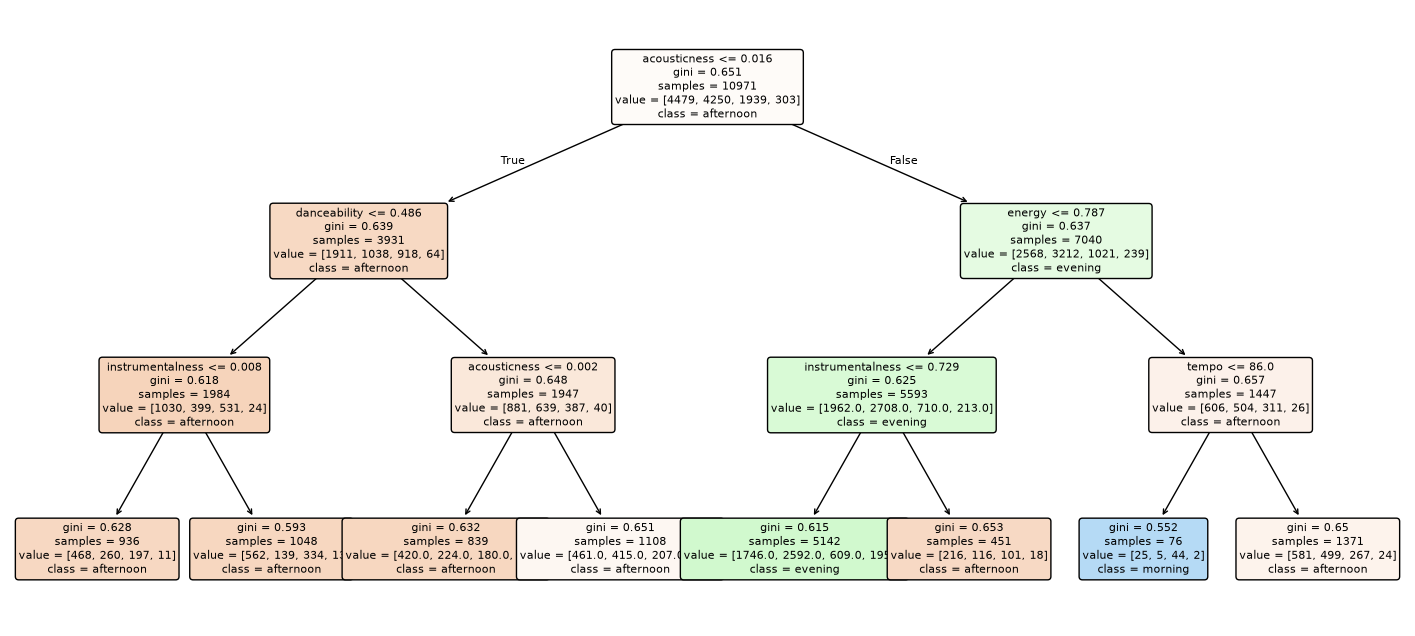

|--- acousticness <= 0.02
|   |--- danceability <= 0.49
|   |   |--- instrumentalness <= 0.01
|   |   |   |--- class: afternoon
|   |   |--- instrumentalness >  0.01
|   |   |   |--- class: afternoon
|   |--- danceability >  0.49
|   |   |--- acousticness <= 0.00
|   |   |   |--- class: afternoon
|   |   |--- acousticness >  0.00
|   |   |   |--- class: afternoon
|--- acousticness >  0.02
|   |--- energy <= 0.79
|   |   |--- instrumentalness <= 0.73
|   |   |   |--- class: evening
|   |   |--- instrumentalness >  0.73
|   |   |   |--- class: afternoon
|   |--- energy >  0.79
|   |   |--- tempo <= 86.00
|   |   |   |--- class: morning
|   |   |--- tempo >  86.00
|   |   |   |--- class: afternoon

acousticness        0.545702
instrumentalness    0.186687
energy              0.122304
danceability        0.085062
tempo               0.060244
liveness            0.000000
loudness            0.000000
speechiness         0.000000
valence             0.000000
dtype: float64


In [5]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtrain, ytrain)
ypred = tree.predict(Xtest)
print(classification_report(ytest, ypred, zero_division=0))

plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=audio_features, class_names=list(tree.classes_),
          filled=True, rounded=True, fontsize=8)
plt.show()

print(export_text(tree, feature_names=audio_features))
print(pd.Series(tree.feature_importances_, index=audio_features).sort_values(ascending=False))

### Results

Afternoon and evening are predicted quite frequently (recall 0.62 and 0.54), but morning recall is 0.01 and night recall is 0.00. The tree almost never predicts morning or night, so really it is choosing between afternoon and evening

Acousticness is the most important feature (about 0.55), followed by instrumentalness (0.19), energy (0.12), danceability (0.09) and tempo (0.06)

The other four features were unused. The first split is on acousticness, where low-acousticness tracks are predicted as afternoon, and in the more acoustic branch, tracks with lower energy are predicted as evening. 

The only rule that predicts morning is high energy (above 0.79) with a tempo of 86 or below, which covers few plays

### Confusion matrix

Each row is the time of day the model predicted and each column is the true time of day, so correct predictions sit on the diagonal.

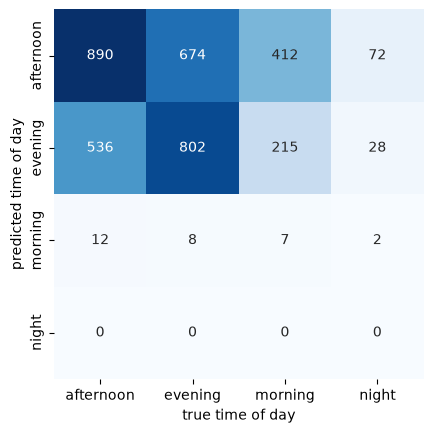

In [7]:
mat = confusion_matrix(ytest, ypred, labels=tree.classes_)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=tree.classes_, yticklabels=tree.classes_)
plt.xlabel('true time of day')
plt.ylabel('predicted time of day')
plt.show()

The matrix confirms that most of the diagonal is in the afternoon and evening cells

The model is not separating the four times of day, only afternoon from evening, and only weakly

## Conclusion

Audio features carry a little information about when I listen, acousticness being the dominant feature that separates my afternoon plays from my evening plays, but the signal is weak. 

The tree beats the always guess evening baseline by about 5 points and does not identify morning or night at all

Limitations: 3,370 plays were dropped for missing audio features, the night class is small (405 plays), the time-ordered test set covers only the most recent period of my listening